In [1]:
import pandas as pd

In [2]:
df=pd.read_csv("../data/criteo-uplift-v2.1.csv")
df.shape

(13979592, 16)

In [3]:
df.head()

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0


In [4]:
df.columns


Index(['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10',
       'f11', 'treatment', 'conversion', 'visit', 'exposure'],
      dtype='str')

In [5]:
df.groupby("treatment")[["f0","f1","f2","f3","f4","f5","f6","f7","f8","f9","f10","f11"]].mean()

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11
treatment,,,,,,,,,,,,
0,19.651705,10.067935,8.448173,4.232821,10.336526,4.039339,-3.999880,5.080284,3.934652,15.886253,5.331898,-0.170868
1,19.614755,10.070337,8.446302,4.169412,10.339245,4.026602,-4.182792,5.105555,3.933392,16.052589,5.333660,-0.170985


In [6]:
df['treatment'].value_counts()

treatment
1    11882655
0     2096937
Name: count, dtype: int64

In [7]:

treated_rate= df[df["treatment"] == 1]["conversion"].mean()
print(treated_rate)


0.0030894610674129645


In [8]:
control_rate=df[df["treatment"] == 0]["conversion"].mean()
print(control_rate)

0.0019375880152813366


In [9]:
uplift= treated_rate - control_rate
print(uplift)

0.0011518730521316279


In [10]:
treated_visit_rate = df[df["treatment"] == 1]["visit"].mean()
control_visit_rate = df[df["treatment"] == 0]["visit"].mean()
uplift_visit = treated_visit_rate - control_visit_rate
print(treated_visit_rate, control_visit_rate, uplift_visit)

0.048543360048743316 0.03820095691954503 0.010342403129198284


In [11]:
df.isnull().sum()

f0            0
f1            0
f2            0
f3            0
f4            0
f5            0
f6            0
f7            0
f8            0
f9            0
f10           0
f11           0
treatment     0
conversion    0
visit         0
exposure      0
dtype: int64

In [12]:
df.describe()

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
count,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07
mean,1.962030e+01,1.006998e+01,8.446582e+00,4.178923e+00,1.033884e+01,4.028513e+00,-4.155356e+00,5.101765e+00,3.933581e+00,1.602764e+01,5.333396e+00,-1.709672e-01,8.500001e-01,2.916680e-03,4.699200e-02,3.063122e-02
std,5.377464e+00,1.047557e-01,2.993161e-01,1.336645e+00,3.433081e-01,4.310974e-01,4.577914e+00,1.205248e+00,5.665958e-02,7.018975e+00,1.682288e-01,2.283277e-02,3.570713e-01,5.392748e-02,2.116217e-01,1.723164e-01
min,1.261636e+01,1.005965e+01,8.214383e+00,-8.398387e+00,1.028053e+01,-9.011892e+00,-3.142978e+01,4.833815e+00,3.635107e+00,1.319006e+01,5.300375e+00,-1.383941e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.261636e+01,1.005965e+01,8.214383e+00,4.679882e+00,1.028053e+01,4.115453e+00,-6.699321e+00,4.833815e+00,3.910792e+00,1.319006e+01,5.300375e+00,-1.686792e-01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.192341e+01,1.005965e+01,8.214383e+00,4.679882e+00,1.028053e+01,4.115453e+00,-2.411115e+00,4.833815e+00,3.971858e+00,1.319006e+01,5.300375e+00,-1.686792e-01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,2.443646e+01,1.005965e+01,8.723335e+00,4.679882e+00,1.028053e+01,4.115453e+00,2.944427e-01,4.833815e+00,3.971858e+00,1.319006e+01,5.300375e+00,-1.686792e-01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,2.674526e+01,1.634419e+01,9.051962e+00,4.679882e+00,2.112351e+01,4.115453e+00,2.944427e-01,1.199840e+01,3.971858e+00,7.529502e+01,6.473917e+00,-1.686792e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


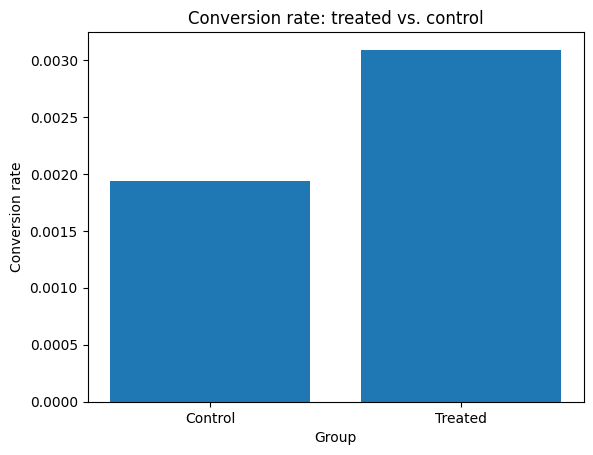

In [13]:
import matplotlib.pyplot as plt


plt.title("Conversion rate: treated vs. control")
plt.ylabel("Conversion rate")
plt.xlabel("Group")
plt.bar(["Control", "Treated"], [control_rate, treated_rate])

plt.savefig("../outputs/conversion_uplift.png", dpi=150, bbox_inches="tight")
plt.show()

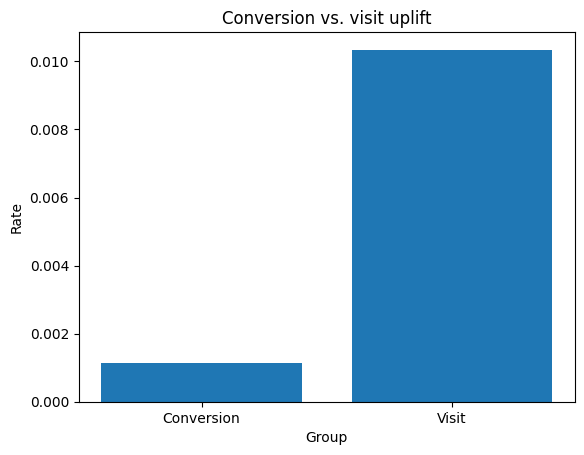

In [14]:
plt.title("Conversion vs. visit uplift")
plt.xlabel("Group")
plt.ylabel("Rate")
plt.bar(["Conversion","Visit"],[uplift,uplift_visit])
plt.savefig("../outputs/conversionVsvisit.png", dpi=150, bbox_inches="tight")
plt.show()


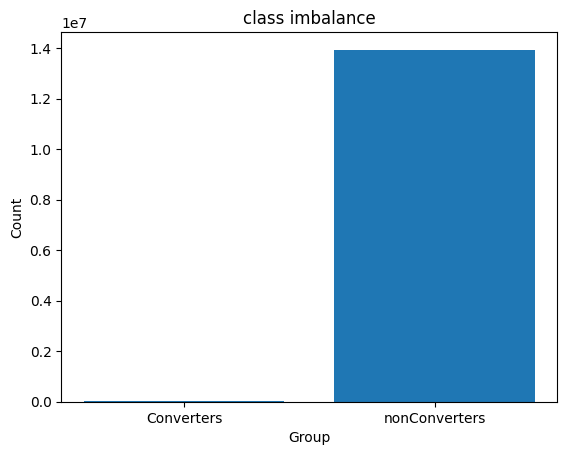

In [15]:
plt.title("class imbalance")
plt.xlabel("Group")
plt.ylabel("Count")
plt.bar(["Converters","nonConverters"],[(df["conversion"]==1).sum(),(df["conversion"]==0).sum()])
plt.savefig("../outputs/class_imbalance.png", dpi=150, bbox_inches="tight")
plt.show()


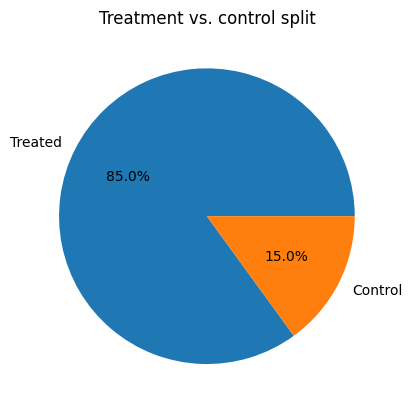

In [16]:
treated_count = (df["treatment"] == 1).sum()
control_count = (df["treatment"] == 0).sum()
plt.pie([treated_count, control_count],
        labels=["Treated", "Control"],
        autopct="%1.1f%%")
plt.title("Treatment vs. control split")
plt.savefig("../outputs/treatment_split.png", dpi=150, bbox_inches="tight")
plt.show()

# EDA Summary — Criteo Uplift Dataset

## Dataset overview
- 13,979,592 rows × 16 columns.
- Columns: 12 anonymized features (f0–f11), a treatment flag, and three
  outcome columns (conversion, visit, exposure).
- Data health: no missing values were found in any column, so no imputation
  was required.

## Treatment / control split
- Treated: 11,882,655 (85%) · Control: 2,096,937 (15%).
- The control group is kept deliberately small because withholding ads from
  users means giving up potential sales, so the advertiser holds back only
  enough people to form a reliable baseline for comparison.
- See: outputs/treatment_split.png

## Key finding 1 — Average treatment effect on conversion
- Control conversion rate: 0.00194 (0.194%)
- Treated conversion rate: 0.00309 (0.309%)
- Uplift: 0.00115 absolute, roughly a 60% relative increase.
- Advertising has a clear positive effect on average: users who could be shown
  an ad converted about 60% more often than those who

In [17]:
sample_df = df.groupby(["treatment", "conversion"], group_keys=False).sample(frac=0.07, random_state=42)

In [18]:
sample_df.shape

(978571, 16)

In [19]:
sample_df["treatment"].value_counts(normalize=True)

treatment
1    0.850001
0    0.149999
Name: proportion, dtype: float64

In [20]:
sample_df["conversion"].value_counts()

conversion
0    975717
1      2854
Name: count, dtype: int64

In [21]:
from sklearn.model_selection import train_test_split
train_sample_df, test_sample_df = train_test_split(
    sample_df,
    test_size=0.2,
    random_state=42,
    stratify=sample_df[["treatment", "conversion"]]
)

In [22]:
print(train_sample_df.shape, test_sample_df.shape)
print(train_sample_df["treatment"].value_counts(normalize=True))
print(test_sample_df["treatment"].value_counts(normalize=True))

(782856, 16) (195715, 16)
treatment
1    0.850001
0    0.149999
Name: proportion, dtype: float64
treatment
1    0.850001
0    0.149999
Name: proportion, dtype: float64


In [23]:
features = [f"f{i}" for i in range(12)]
X_train = train_sample_df[features]
Y_train = train_sample_df["conversion"]

In [24]:
print(X_train.shape,Y_train.shape)


(782856, 12) (782856,)


In [25]:
treated = train_sample_df[train_sample_df["treatment"] == 1]
X_train_treated = treated[features]
y_train_treated = treated["conversion"]

In [26]:
controled = train_sample_df[train_sample_df["treatment"] == 0]
X_train_control = controled[features]
y_train_control = controled["conversion"]

In [27]:
print(X_train_treated.shape, X_train_control.shape)

(665428, 12) (117428, 12)


In [28]:
from sklearn.linear_model import LogisticRegression

model_treated = LogisticRegression(max_iter=1000)
model_treated.fit(X_train_treated, y_train_treated)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [29]:

model_control = LogisticRegression(max_iter=1000)
model_control.fit(X_train_control, y_train_control)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [30]:
X_test=test_sample_df[features]

In [31]:
p_treated = model_treated.predict_proba(X_test)[:, 1]
p_control = model_control.predict_proba(X_test)[:, 1]

In [32]:
uplift = p_treated - p_control

In [33]:
print(uplift[:10])                 # first 10 users' individual uplift
print(uplift.mean())               # average across the test set
print(uplift.min(), uplift.max())  # the full range

[0.00043234 0.00011109 0.0009162  0.00017933 0.00011434 0.00010807
 0.00019423 0.00014746 0.00108834 0.00072385]
0.0009686512818683199
-0.001906923639165307 0.2709246436387698


In [34]:
y_test = test_sample_df["conversion"]
treatment_test = test_sample_df["treatment"]

In [35]:
print(len(y_test), len(treatment_test), len(uplift))

195715 195715 195715


In [36]:
!pip install scikit-uplift

In [37]:
!python3 -m pip install scikit-uplift

In [38]:
from sklift.metrics import qini_auc_score
from sklift.viz import plot_qini_curve

ImportError: cannot import name 'check_matplotlib_support' from 'sklearn.utils' (/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/__init__.py)

In [ ]:
from sklift.metrics import qini_auc_score
qini = qini_auc_score(y_test, uplift, treatment_test)
print(qini)

In [ ]:
from sklift.metrics import qini_curve

x_actual, y_actual = qini_curve(y_test, uplift, treatment_test)

In [ ]:
plt.plot(x_actual, y_actual, label="Model")
plt.xlabel("Number of users targeted")
plt.ylabel("Cumulative incremental conversions")
plt.title("Qini curve")
plt.plot([x_actual[0], x_actual[-1]], [y_actual[0], y_actual[-1]],
         linestyle="--", label="Random")
plt.legend()
plt.savefig("../outputs/qini_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [40]:
results = test_sample_df[["treatment", "conversion"]].copy()
results["uplift"] = uplift
results.to_csv("../outputs/uplift_results.csv", index=False)